# Zela | Machine Learning & Modelling

## 1. Origem dos dados

Para o modelo, partimos de um dataset real e geramos uma versão simulada a partir dele. A base real é a *Five Vital Signs of Normal People*, publicada no Zenodo (https://zenodo.org/records/5549632?preview_file=five+vital+signs+of+normal+people.csv). Ela traz os sinais vitais de 102 pessoas sem doença, medidos por um médico 3 vezes por dia durante 3 dias, ou seja, 9 leituras por pessoa. Os sinais são pressão diastólica, pressão sistólica, frequência cardíaca, saturação de oxigênio e temperatura. O dataset tem 102 linhas, uma por pessoa, e 46 colunas, com o ID e as 9 leituras de cada um dos 5 sinais.

Simulamos porque não existe base pública de pessoas piorando enquanto esperam no pronto-socorro, que é justamente o que a Zela observa. Para cada pessoa, usamos a mediana das 9 leituras como o "normal" dela e, a partir disso, geramos 36 leituras seguidas, uma a cada 2 minutos (0 a 70 min de espera), como se a pulseira estivesse medindo na sala de espera. Cada pessoa recebeu um destes cenários, estável, frequência cardíaca subindo, saturação de oxigênio caindo, combinado ou recuperação. Os sinais mudam aos poucos conforme o cenário (a temperatura sobe bem mais no combinado e no de frequência cardíaca subindo), e colocamos um pequeno ruído para não ficar artificialmente liso. A base final tem 3.672 linhas (102 pessoas × 36 leituras) e 13 colunas, com a data e a hora de cada leitura.

Os cenários e o tamanho de cada mudança foram definidos pelo grupo e não seguem um critério clínico. A base real só tem pessoas saudáveis e não informa idade, país nem o aparelho usado. Por isso, o modelo aprende o padrão da nossa simulação. Antes de ser usado em um cenário real, ele precisaria ser treinado com dados reais de pronto-socorro.


# 2. Análise dos dados

In [1]:
# importando as bibliotecas necessárias para a análise do dataset e visualização em gráficos
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# carregando o dataset
df = pd.read_csv('dados/medicoes_pulseira_simuladas.csv')


In [2]:
df.shape # número de linhas e colunas

(3672, 13)

In [3]:
df.info() # informações dos dados

<class 'pandas.DataFrame'>
RangeIndex: 3672 entries, 0 to 3671
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   paciente_id          3672 non-null   int64  
 1   dispositivo_id       3672 non-null   str    
 2   leitura_numero       3672 non-null   int64  
 3   tempo_espera_min     3672 non-null   int64  
 4   dt_medicao           3672 non-null   str    
 5   frequencia_cardiaca  3672 non-null   int64  
 6   spo2                 3672 non-null   float64
 7   temperatura          3672 non-null   float64
 8   pressao_sistolica    3672 non-null   int64  
 9   pressao_diastolica   3672 non-null   int64  
 10  cenario_simulado     3672 non-null   str    
 11  origem_dado          3672 non-null   str    
 12  fonte_referencia     3672 non-null   str    
dtypes: float64(2), int64(6), str(5)
memory usage: 373.1 KB


In [4]:
df.head() # primeiras 5 linhas

,paciente_id,dispositivo_id,leitura_numero,tempo_espera_min,dt_medicao,frequencia_cardiaca,spo2,temperatura,pressao_sistolica,pressao_diastolica,cenario_simulado,origem_dado,fonte_referencia
0,1,ESP32-0001,1,0,2026-11-10 14:00:00,74,97.1,35.87,112,67,ESTAVEL,SIMULADO,Simulado - faixas inspiradas no dataset Zenodo...
1,1,ESP32-0001,2,2,2026-11-10 14:02:00,73,96.9,35.92,111,66,ESTAVEL,SIMULADO,Simulado - faixas inspiradas no dataset Zenodo...
2,1,ESP32-0001,3,4,2026-11-10 14:04:00,75,97.2,35.94,110,67,ESTAVEL,SIMULADO,Simulado - faixas inspiradas no dataset Zenodo...
3,1,ESP32-0001,4,6,2026-11-10 14:06:00,74,97.0,35.99,110,64,ESTAVEL,SIMULADO,Simulado - faixas inspiradas no dataset Zenodo...
4,1,ESP32-0001,5,8,2026-11-10 14:08:00,73,97.3,35.98,109,66,ESTAVEL,SIMULADO,Simulado - faixas inspiradas no dataset Zenodo...


Podemos ver que o dataset tem 3672 linhas e 13 colunas, cada linha é um momento da espera de um paciente, as colunas trazem a identificação, o tempo de espera, a data e a hora da leitura, os 5 sinais vitais e o cenário simulado. Todas as linhas e colunas estão preenchidas, nenhum valor é nulo. 8 colunas são numéricas e 5 são de texto, e a data e hora (`dt_medicao`) vem como texto. Dos 5 sinais, a pulseira real só mede frequência cardíaca, SpO2 e temperatura, então a pressão sistólica e a diastólica ficam só na análise e não entram no modelo.

| Coluna | O que é | Unidade / valores |
|---|---|---|
| paciente_id | identificador da pessoa | 1 a 102 |
| dispositivo_id | identificador da pulseira, uma por pessoa | ESP32-0001 a ESP32-0102 |
| leitura_numero | ordem da leitura daquela pessoa | 1 a 36 |
| tempo_espera_min | minutos desde a chegada na sala de espera | 0 a 70, de 2 em 2 |
| dt_medicao | data e hora da leitura | de 2026-11-10 14:00 a 23:35 |
| frequencia_cardiaca | batimentos do coração por minuto | bpm |
| spo2 | saturação de oxigênio no sangue | % |
| temperatura | temperatura corporal | °C |
| pressao_sistolica | pressão arterial máxima | mmHg |
| pressao_diastolica | pressão arterial mínima | mmHg |
| cenario_simulado | cenário atribuído à pessoa na simulação | ESTAVEL, FC_ELEVANDO, SPO2_CAINDO, COMBINADO, RECUPERACAO |
| origem_dado | indica que a linha é simulada | sempre "SIMULADO" |
| fonte_referencia | de onde vieram as faixas da simulação | sempre o mesmo texto: simulado, com faixas inspiradas no Zenodo |


In [5]:
df.isna().sum() # verificar valores nulos

paciente_id            0
dispositivo_id         0
leitura_numero         0
tempo_espera_min       0
dt_medicao             0
frequencia_cardiaca    0
spo2                   0
temperatura            0
pressao_sistolica      0
pressao_diastolica     0
cenario_simulado       0
origem_dado            0
fonte_referencia       0
dtype: int64

In [6]:
df.duplicated().sum() # verificar duplicatas

np.int64(0)

Analisamos que não há nenhum dado faltante, assim como vimos antes, e nem dado duplicado. Isso já era esperado, porque a base foi gerada artificialmente.

In [7]:
# dt_medicao é a data e a hora da leitura, conferimos se ela concorda com o tempo de espera
df['dt_medicao'] = pd.to_datetime(df['dt_medicao'])
minutos = (df['dt_medicao'] - df.groupby('paciente_id')['dt_medicao'].transform('min')).dt.total_seconds() / 60
print('dt_medicao vai de', df['dt_medicao'].min(), 'até', df['dt_medicao'].max())
print('Leituras em que dt_medicao não bate com tempo_espera_min:', (minutos != df['tempo_espera_min']).sum())

dt_medicao vai de 2026-11-10 14:00:00 até 2026-11-10 23:35:00
Leituras em que dt_medicao não bate com tempo_espera_min: 0


A coluna `dt_medicao` guarda a data e a hora de cada leitura. Conferimos que ela concorda com o `tempo_espera_min`, sem nenhuma diferença nas 3.672 leituras, porque cada paciente chega num horário e as leituras seguem de 2 em 2 minutos. Como ela só repete o tempo de espera, e o horário de chegada não diz nada sobre o estado do paciente, a coluna não entra como feature.

In [8]:
df[['frequencia_cardiaca', 'spo2', 'temperatura', 'pressao_sistolica', 'pressao_diastolica']].describe().round(2)

,frequencia_cardiaca,spo2,temperatura,pressao_sistolica,pressao_diastolica
count,3672.00,3672.00,3672.00,3672.00,3672.00
mean,95.76,94.81,36.66,104.48,69.16
std,18.46,3.91,1.07,11.26,7.14
min,59.00,82.30,34.57,71.00,47.00
25%,81.00,92.20,35.87,96.00,64.00
50%,95.00,95.95,36.59,105.00,69.00
75%,107.00,97.90,37.15,113.00,74.00
max,151.00,100.00,40.42,136.00,89.00


Na frequência cardíaca, o desvio padrão `18` é o maior em relação à média `96` entre os sinais, porque nos cenários de piora que simulamos os batimentos sobem bastante. Na saturação de oxigênio, a média fica em `94,8%`, um pouco abaixo do que uma pessoa saudável costuma ter (95% ou mais), e o mínimo chega a `82%`, mostrando o efeito dos cenários de queda de saturação. A temperatura tem desvio padrão de `1,1 °C` e chega a `40,4 °C` nos cenários de piora, acima do limite crítico de `39 °C`, mas o mínimo é baixo, `34,6 °C`. Esse mínimo vem da base original, que não informa como a temperatura foi medida, e tratamos como uma inconsistência. As pressões variam menos que a frequência cardíaca, a sistólica tem média de `104` e máximo de `136`, e a diastólica tem média de `69` e máximo de `89`. Essa variação vem dos cenários simulados e das diferenças entre as pessoas. As pressões ficam só nesta análise, porque a pulseira não mede pressão arterial e o modelo não poderia usá-las.

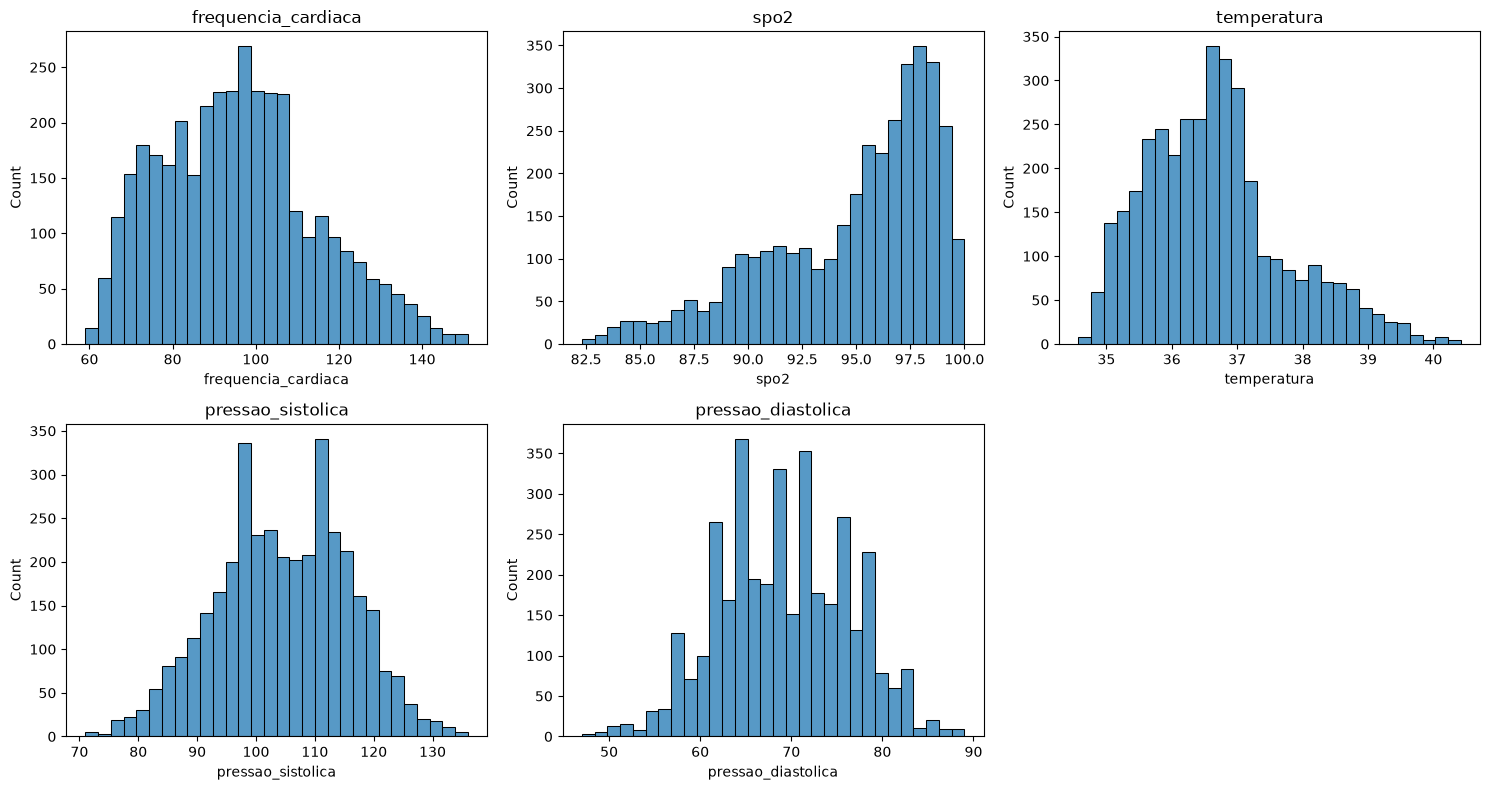

In [9]:
# histograma de cada sinal vital mostrando como os valores se distribuem
sinais = ['frequencia_cardiaca', 'spo2', 'temperatura', 'pressao_sistolica', 'pressao_diastolica']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, coluna in zip(axes.flat, sinais):
    sns.histplot(data=df, x=coluna, bins=30, ax=ax)
    ax.set_title(coluna)
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

Nos histogramas, a frequência cardíaca tem uma cauda para a direita. Isso acontece porque, nos cenários de piora que simulamos, os batimentos sobem muito, mas só nas leituras mais avançadas da espera, então esses valores são poucos. Na saturação de oxigênio acontece o mesmo, mas com uma cauda para a esquerda. A temperatura também tem uma cauda para a direita, porque ela só passa dos 38 °C nos cenários de piora, nas leituras mais avançadas da espera.

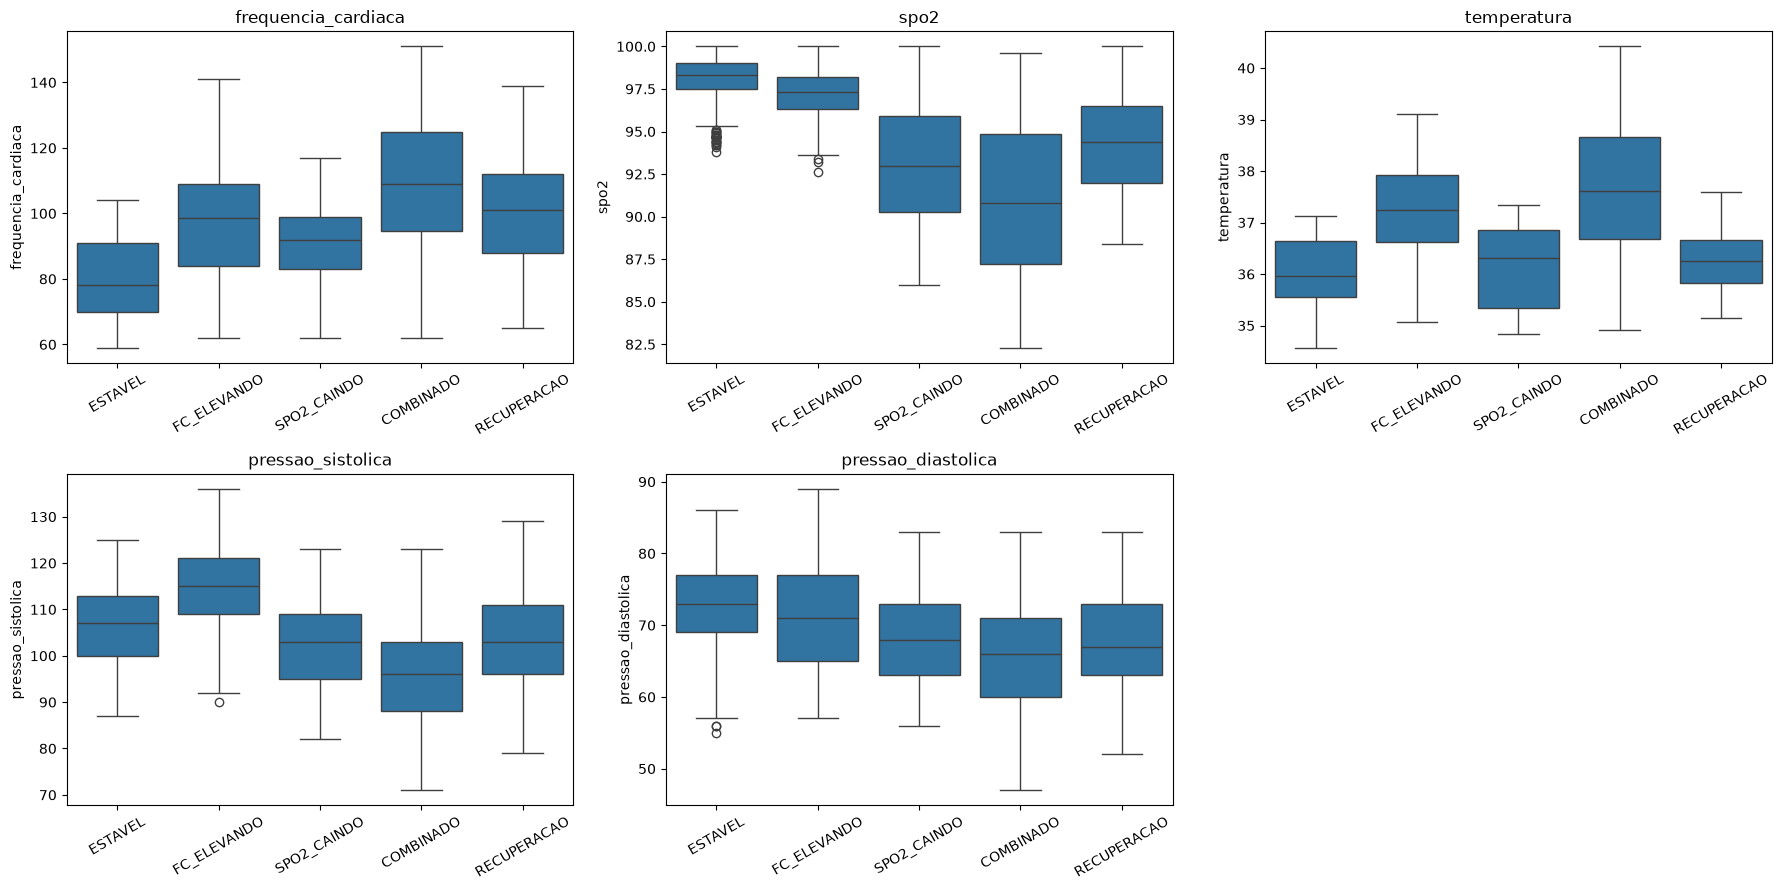

In [10]:
# boxplot de cada sinal por cenário comparando os cenários entre si
ordem = ['ESTAVEL', 'FC_ELEVANDO', 'SPO2_CAINDO', 'COMBINADO', 'RECUPERACAO']

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, coluna in zip(axes.flat, sinais):
    sns.boxplot(data=df, x='cenario_simulado', y=coluna, order=ordem, ax=ax)
    ax.set_title(coluna)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

No boxplot, a caixa da frequência cardíaca do cenário estável é mais baixa e mais estreita que as outras, o que ajuda o modelo a separar quem está estável de quem está piorando. Ainda assim, as caixas se sobrepõem na parte de baixo, por causa das leituras do começo da espera. Na saturação de oxigênio, o cenário estável tem vários outliers, mas eles não são erros, são pessoas que já têm a saturação normal um pouco mais baixa, um dado que vem da base real. Por isso não vamos removê-los, e a variação em relação à primeira leitura de cada pessoa ajuda o modelo a lidar com essa diferença. Na temperatura, o combinado e o de frequência cardíaca subindo têm caixas mais altas que o estável (médias de `37,7` e `37,2 °C` contra `36,0 °C`), e é neles que a temperatura chega a passar de 39 °C.

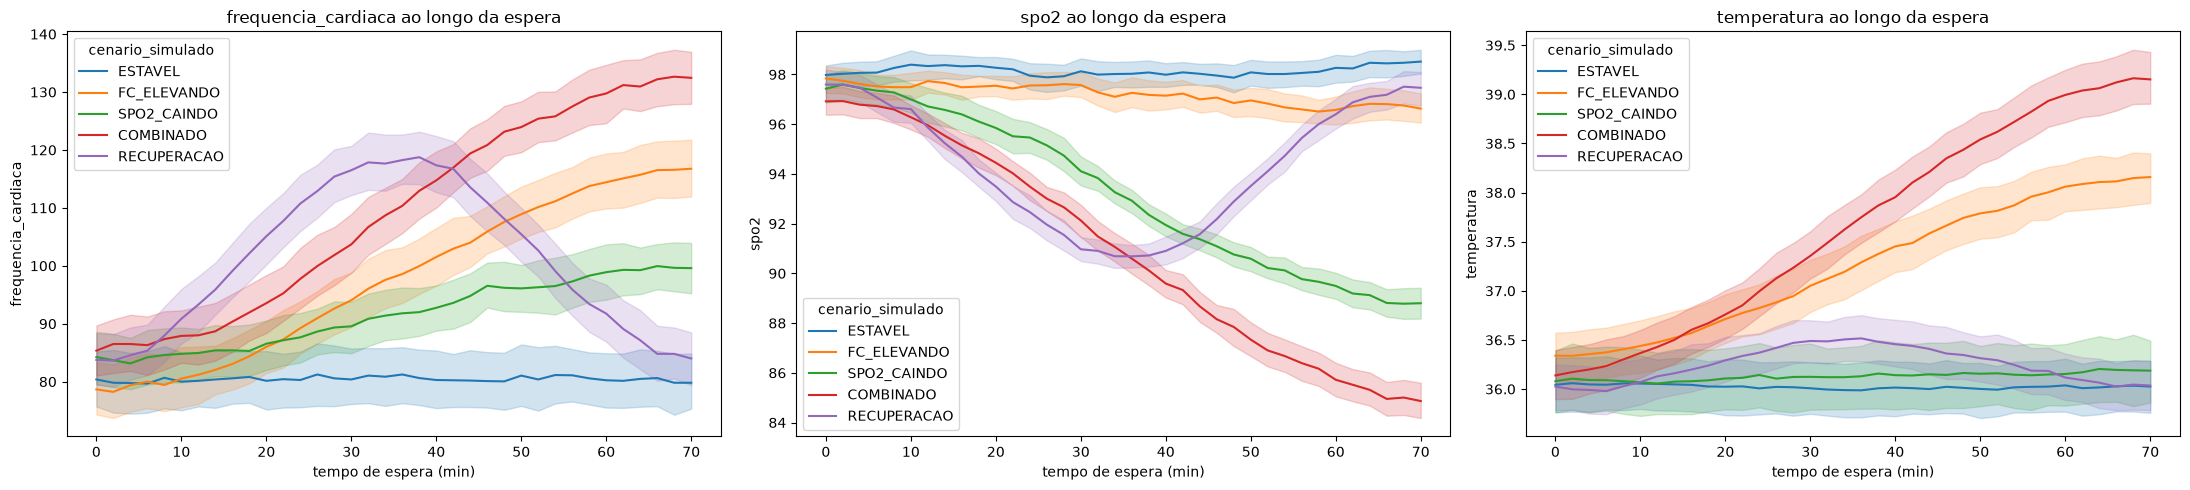

In [11]:
# média de FC, SpO2 e temperatura ao longo da espera, uma linha por cenário
fig, axes = plt.subplots(1, 3, figsize=(22, 5))
for ax, coluna in zip(axes, ['frequencia_cardiaca', 'spo2', 'temperatura']):
    sns.lineplot(data=df, x='tempo_espera_min', y=coluna, hue='cenario_simulado', hue_order=ordem, ax=ax)
    ax.set_title(f'{coluna} ao longo da espera')
    ax.set_xlabel('tempo de espera (min)')
plt.tight_layout()
plt.show()

No gráfico de linhas, no começo da espera todos os cenários são muito parecidos, porque cada pessoa parte do seu próprio normal. Por isso o modelo deve errar no início da espera. A recuperação piora até por volta dos 40 minutos e depois volta a ficar próxima da estável no final. Mesmo assim, decidimos considerar a recuperação como piora, porque quem piorou na espera precisa de atenção e pode voltar a piorar. Para o modelo não esquecer essa piora, vamos usar a maior variação até o momento como feature. A temperatura sobe devagar no combinado e no de frequência cardíaca subindo, e a média do combinado chega a `39 °C` perto dos 60 minutos, enquanto nos cenários estável, SpO2 caindo e recuperação ela fica entre 36 e 36,5 °C.

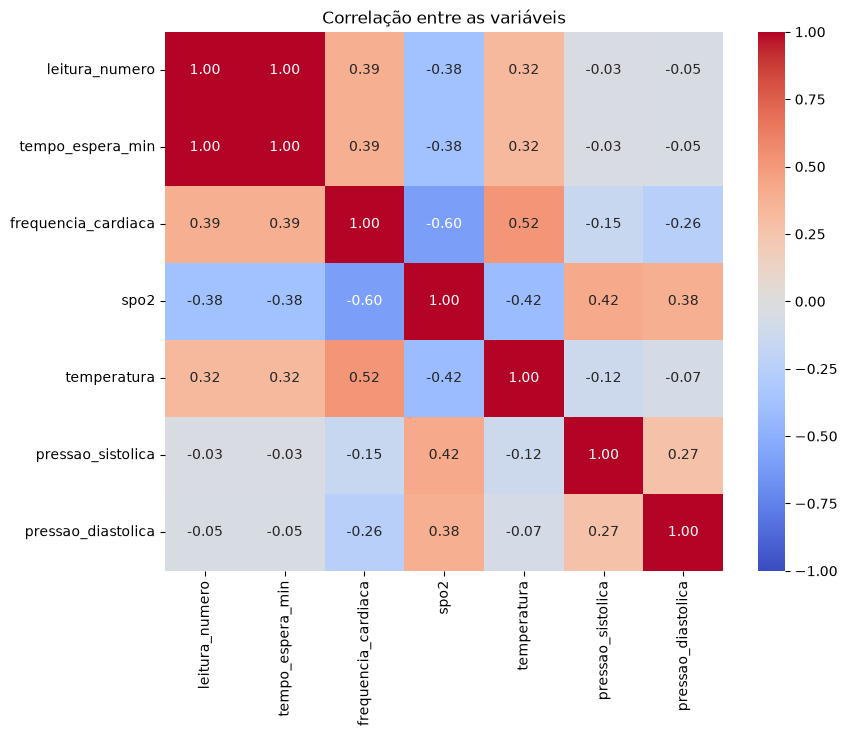

In [12]:
# correlação entre as variáveis numéricas de -1 (uma sobe, a outra desce) a 1 (sobem juntas)
numericas = ['leitura_numero', 'tempo_espera_min'] + sinais

plt.figure(figsize=(9, 7))
sns.heatmap(df[numericas].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlação entre as variáveis')
plt.show()

No mapa de correlação, `leitura_numero` e `tempo_espera_min` têm correlação `1,00`, porque um aumenta junto com o outro. Como carregam a mesma informação, vamos manter só tempo_espera_min no modelo. Entre os sinais, a relação mais forte é entre frequência cardíaca e saturação `-0,60`, quando os batimentos sobem, a saturação tende a cair, porque nos cenários de piora que simulamos as duas mudam ao mesmo tempo. O tempo de espera tem correlação moderada com a frequência cardíaca `0,39` e com a saturação `−0,38`, mostrando que, em média, os pacientes pioram conforme a espera passa. Já as pressões sistólica e diastólica têm correlação fraca `0,27`, diferente do que se espera na vida real, porque a simulação aplica um ruído separado em cada uma. A temperatura tem correlação de `0,52` com a frequência cardíaca, `−0,42` com a saturação e `0,32` com o tempo de espera, ou seja, também sobe junto com a piora. Como a pulseira não mede pressão, essas duas colunas não entram no modelo.

In [13]:
# regra de crítico, a mesma do monitor em Python e da pulseira (FC, SpO2 e temperatura)
df = df.sort_values(['paciente_id', 'tempo_espera_min'])
df['critico'] = ((df['frequencia_cardiaca'] >= 130) | (df['spo2'] < 90) | (df['temperatura'] >= 39.0)).astype(int)

# alvo: alguma das próximas 5 leituras (10 min) do mesmo paciente é crítica?
proximas = [df.groupby('paciente_id')['critico'].shift(-k) for k in range(1, 6)]
df['vai_ficar_critico'] = pd.concat(proximas, axis=1).max(axis=1)

df[['paciente_id', 'tempo_espera_min', 'frequencia_cardiaca', 'spo2', 'temperatura', 'critico', 'vai_ficar_critico']].head(40)

,paciente_id,tempo_espera_min,frequencia_cardiaca,spo2,temperatura,critico,vai_ficar_critico
0,1,0,74,97.1,35.87,0,0.0
1,1,2,73,96.9,35.92,0,0.0
2,1,4,75,97.2,35.94,0,0.0
3,1,6,74,97.0,35.99,0,0.0
4,1,8,73,97.3,35.98,0,0.0
5,1,10,77,96.9,36.08,0,0.0
6,1,12,74,97.5,36.12,0,0.0
7,1,14,76,97.2,36.06,0,0.0
8,1,16,76,96.8,35.98,0,0.0
9,1,18,77,97.9,35.93,0,0.0


Leituras para o modelo: 3027
vai_ficar_critico
0.0    0.907
1.0    0.093
Name: proportion, dtype: float64


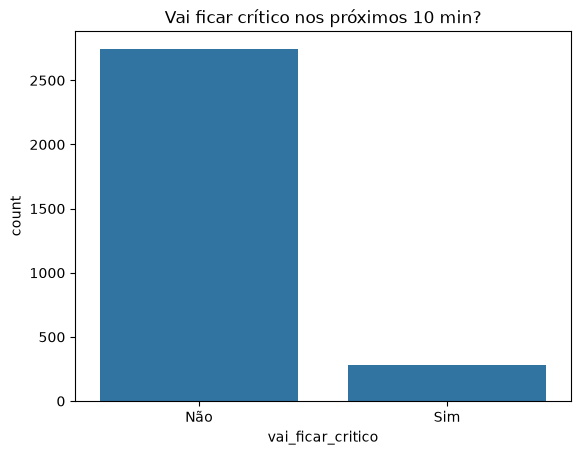

In [14]:
# o modelo só faz sentido para quem ainda NÃO está crítico e tem leituras futuras
base = df[(df['critico'] == 0) & df['vai_ficar_critico'].notna()]

print('Leituras para o modelo:', len(base))
print(base['vai_ficar_critico'].value_counts(normalize=True).round(3))

sns.countplot(data=base, x='vai_ficar_critico')
plt.title('Vai ficar crítico nos próximos 10 min?')
plt.xticks([0, 1], ['Não', 'Sim'])
plt.show()

O alvo é `vai_ficar_critico`, o modelo tenta prever se, nos próximos 10 minutos, o paciente vai chegar ao nível crítico. Se só classificássemos o estado atual, seria uma detecção, e isso a regra da pulseira já faz. Como a base real não tem horário nem pacientes piorando, criamos esse target experimental a partir dos cenários simulados, usando só as informações disponíveis até o momento da leitura.

O nível crítico segue a regra da pulseira e do monitor em Python, frequência cardíaca de 130 bpm ou mais, SpO2 abaixo de 90% ou temperatura de 39,0 °C ou mais. A temperatura entrou na regra porque a pulseira também lê a temperatura, e assim o crítico do modelo é o mesmo que a equipe veria na pulseira. No total, 122 leituras passam de 39,0 °C, em 15 pacientes, e 6 leituras de 3 pacientes ficaram críticas só pela temperatura, as outras já eram críticas pela frequência cardíaca ou pela saturação.

As leituras que já são críticas saem da base, porque a pulseira já captou esse estado e não há o que prever. A última leitura de cada paciente também sai, porque não tem leituras futuras para dizer se ele ficou crítico.

A base é desbalanceada, 91% das leituras são "não" e só 9% são "sim". Isso acontece porque, mesmo nos cenários de piora, só as leituras dos 10 minutos antes de virar crítico entram como "sim". Por isso a acurácia engana, um modelo que sempre respondesse "não" acertaria 91% sem servir para nada. Vamos olhar principalmente o recall e a precisão.

# 3. Inconsistências e conclusões da análise

**Valores estranhos**

Na base original havia alguns dados inconsistentes, como saturação de oxigênio acima de 100% (até 102%) e temperatura muito baixa (até 33,1 °C). Não sabemos o motivo, porque a base original não informa como as medições foram feitas. Na nossa base, a saturação acima de 100% não aparece, porque a simulação limita a SpO2 em 100%. A temperatura baixa continua, com 85 leituras abaixo de 35 °C, de 8 pacientes. Uma hipótese é que a temperatura tenha sido medida na pele ou no pulso, que fica abaixo da temperatura interna do corpo. Decidimos manter a temperatura, porque a pulseira mede temperatura de verdade e as leituras baixas não atrapalham a regra de crítico, que olha só para temperaturas altas (39,0 °C ou mais).

**Colunas que saem do modelo**

- `leitura_numero` é a mesma informação do `tempo_espera_min`. Não precisamos dessa redundância.
- `paciente_id` e `dispositivo_id` são identificadores e não dizem nada sobre o estado do paciente. O `paciente_id` só fica guardado para separar treino e teste por paciente.
- `origem_dado` e `fonte_referencia` têm o mesmo valor em todas as linhas, então não ajudam o modelo.
- `cenario_simulado` entrega a resposta, porque diz se o paciente vai piorar, e a pulseira real não teria essa informação. Usar essa coluna seria data leakage.
- `pressao_sistolica` e `pressao_diastolica` ficam na análise, mas saem do modelo, porque a pulseira (ESP32) só mede frequência cardíaca, SpO2 e temperatura. Em uso real o modelo não teria essa informação.
- `dt_medicao` é a data e a hora da leitura e só repete o `tempo_espera_min`, além de mostrar o horário em que cada paciente chegou, que não diz nada sobre o estado dele.

**O que a EDA nos mostrou**

- No começo da espera, todos os cenários são muito parecidos, então o modelo deve errar mais nesse período.
- Frequência cardíaca e saturação de oxigênio são os sinais que mais separam os cenários, e a temperatura também separa o combinado e o de frequência cardíaca subindo.
- Cada pessoa tem um normal diferente, então vamos criar as features de variação desde a primeira leitura e de maior variação até agora.
- A base é desbalanceada, só 9% das leituras são "vai ficar crítico", então vamos avaliar principalmente o recall e a precisão.

**Limitação**

A maior limitação da nossa solução é que o alvo é experimental, o modelo aprende o padrão da simulação, não o de pacientes reais. Para usar de verdade, seria necessário validar com dados reais de um pronto-socorro.

# 4. Pré-processamento

In [15]:
# features de variação, comparando cada leitura com o normal da própria pessoa
paciente = df.groupby('paciente_id')

df['fc_variacao'] = df['frequencia_cardiaca'] - paciente['frequencia_cardiaca'].transform('first')
df['spo2_variacao'] = df['spo2'] - paciente['spo2'].transform('first')

# maior variação até agora, guarda a pior piora, mesmo que o paciente melhore depois
df['fc_maior_subida'] = df.groupby('paciente_id')['fc_variacao'].cummax()
df['spo2_maior_queda'] = df.groupby('paciente_id')['spo2_variacao'].cummin()

df[df['paciente_id'] == 3][['tempo_espera_min', 'frequencia_cardiaca', 'fc_variacao', 'fc_maior_subida',
                            'spo2', 'spo2_variacao', 'spo2_maior_queda']].iloc[::5]

,tempo_espera_min,frequencia_cardiaca,fc_variacao,fc_maior_subida,spo2,spo2_variacao,spo2_maior_queda
72,0,90,0,0,96.7,0.0,0.0
77,10,89,-1,0,95.6,-1.1,-1.1
82,20,89,-1,2,94.5,-2.2,-2.4
87,30,92,2,2,94.0,-2.7,-2.7
92,40,98,8,8,91.4,-5.3,-5.3
97,50,99,9,12,89.9,-6.8,-6.8
102,60,102,12,12,90.3,-6.4,-8.1
107,70,106,16,16,88.0,-8.7,-8.9


As features de variação comparam cada leitura com a primeira leitura da própria pessoa, que serve como referência do seu normal. Assim o modelo faz uma comparação mais justa, uma FC de 100 pode ser normal para uma pessoa e uma piora para outra. A maior variação até agora guarda a pior piora que a pessoa já teve na espera, para o modelo não esquecer quem piorou e depois melhorou, porque essa pessoa ainda pode voltar a piorar.

In [16]:
# base do modelo, só leituras ainda não críticas e com leituras futuras
base = df[(df['critico'] == 0) & df['vai_ficar_critico'].notna()].copy()

# entradas (X) e saída (y), as colunas descartadas na EDA e a pressão (a pulseira não mede) ficam de fora
features = ['tempo_espera_min', 'frequencia_cardiaca', 'spo2', 'temperatura',
            'fc_variacao', 'spo2_variacao', 'fc_maior_subida', 'spo2_maior_queda']

X = base[features]
y = base['vai_ficar_critico'].astype(int)
print('X:', X.shape, '| y:', y.shape)

X: (3027, 8) | y: (3027,)


In [17]:
from sklearn.model_selection import train_test_split

# holdout por paciente, todas as leituras de um paciente ficam só no treino ou só no teste
pacientes = base.groupby('paciente_id')['vai_ficar_critico'].max()
treino_ids, teste_ids = train_test_split(pacientes.index, test_size=0.2,
                                         stratify=pacientes, random_state=42)

no_treino = base['paciente_id'].isin(treino_ids)
X_train, X_test = X[no_treino], X[~no_treino]
y_train, y_test = y[no_treino], y[~no_treino]

print('Pacientes  treino:', len(treino_ids), '| teste:', len(teste_ids))
print('Leituras   treino:', len(X_train), '| teste:', len(X_test))
print('% que vai ficar crítico  treino:', round(y_train.mean(), 3), '| teste:', round(y_test.mean(), 3))
print('Pacientes nos dois conjuntos:', len(set(treino_ids) & set(teste_ids)))

Pacientes  treino: 81 | teste: 21
Leituras   treino: 2401 | teste: 626
% que vai ficar crítico  treino: 0.094 | teste: 0.091
Pacientes nos dois conjuntos: 0


O split é feito por paciente, e não por leitura. Se as leituras do mesmo paciente caíssem no treino e no teste, o modelo iria reconhecer esse paciente e decorar os dados dele, e o resultado no teste sairia melhor do que seria com um paciente novo.

In [18]:
from sklearn.preprocessing import StandardScaler

# padronização, média 0 e desvio 1, o fit usa SÓ o treino para o teste não vazar
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

pd.DataFrame(X_train_esc, columns=features).describe().round(2).loc[['mean', 'std']]

,tempo_espera_min,frequencia_cardiaca,spo2,temperatura,fc_variacao,spo2_variacao,fc_maior_subida,spo2_maior_queda
mean,0.0,-0.0,0.0,-0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


O StandardScaler deixa todas as features na mesma escala (média 0 e desvio 1). O modelo só enxerga números, por exemplo uma variação de 5 na saturação de oxigênio é grave, enquanto 5 batimentos a mais na frequência cardíaca mudam pouco, mas sem a padronização a feature com valores maiores acabaria pesando mais. O fit, que calcula a média e o desvio, é feito só com o treino, e o teste é transformado com esses mesmos valores. Se o teste entrasse no cálculo, seria como estudar para a prova com as respostas já prontas.

# 5. Modelo

O nosso problema é de classificação, precisa prever se a leitura vai ficar crítica nos próximos 10 minutos (sim ou não). Escolhemos dois modelos para fazer um comparativo, Regressão Logística e Árvore de Decisão.

A Regressão Logística é o modelo principal, porque na validação cruzada abaixo ela ficou com um equilíbrio melhor que o da árvore de profundidade 2 entre avisar quem vai piorar (recall) e não dar alarme à toa (precisão). Deixar passar um paciente que vai piorar é o erro que mais queremos evitar, mas alarme demais também atrapalha, e isso é explicado depois da validação. Ela depende de escala, então usa os dados padronizados com o StandardScaler.

A Árvore de Decisão entra como comparação, porque gera regras que dá para explicar mais facilmente. Limitamos a árvore a 2 níveis (`max_depth=2`), profundidade escolhida pela validação cruzada porque foi a que mais avisou os pacientes que iam ficar críticos, e para ela não decorar o treino. A árvore não depende de escala, então usa os dados originais.

Nos dois modelos usamos `class_weight='balanced'`, que dá mais peso aos poucos casos de "vai ficar crítico" (9%), para que o modelo não ignore essa classe.

In [19]:
from sklearn.model_selection import cross_validate, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

# validação cruzada só no treino, divide os 81 pacientes do treino em 5 grupos,
# treina em 4 e valida no 5, 5 vezes. O teste fica guardado para o final.
grupos = base.loc[no_treino, 'paciente_id']
validacao = GroupKFold(n_splits=5)

def validar(modelo, X):
    r = cross_validate(modelo, X, y_train, groups=grupos, cv=validacao,
                       scoring=['recall', 'precision', 'f1'], return_train_score=True)
    return {'recall treino': r['train_recall'].mean(), 'recall validação': r['test_recall'].mean(),
            'precisão validação': r['test_precision'].mean(), 'F1 validação': r['test_f1'].mean()}

linhas = {}
for prof in [2, 3, 4, 5, 6, 8, None]:
    arv = DecisionTreeClassifier(max_depth=prof, class_weight='balanced', random_state=42)
    linhas[f'Árvore max_depth={prof}'] = validar(arv, X_train)

# na logística o scaler entra num pipeline, para ser ajustado só com os pacientes de treino de cada rodada
log = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
linhas['Regressão Logística'] = validar(log, X_train)

pd.DataFrame(linhas).T.round(3)

,recall treino,recall validação,precisão validação,F1 validação
Árvore max_depth=2,0.989,0.972,0.371,0.533
Árvore max_depth=3,0.986,0.903,0.411,0.563
Árvore max_depth=4,0.989,0.839,0.465,0.594
Árvore max_depth=5,0.982,0.774,0.477,0.584
Árvore max_depth=6,0.997,0.764,0.486,0.589
Árvore max_depth=8,0.999,0.686,0.518,0.582
Árvore max_depth=None,1.000,0.569,0.611,0.583
Regressão Logística,0.929,0.919,0.431,0.582


**Escolha do modelo e sinais de overfitting.** Fizemos as escolhas pela validação cruzada dentro do treino, sem olhar o teste.

Na árvore, a versão sem limite (`None`) é o retrato do overfitting, porque acerta 100% no treino, mas na validação o recall cai para cerca de 0,57, sinal de que ela decorou os pacientes de treino. Quanto mais rasa a árvore, maior o recall, e a de profundidade 2 teve o maior de todos (0,97). Escolhemos `max_depth=2`, e a árvore fica pequena o bastante para ser explicada.

**Por que a Regressão Logística é o modelo principal.** Mesmo com a árvore de profundidade 2 tendo recall maior (0,97 contra 0,92), a logística continua sendo o modelo principal. A árvore quase não deixa ninguém passar, mas a precisão dela é 0,37, ou seja, uns 6 em cada 10 avisos são alarme falso. Na sala de espera, alarme demais faz a equipe parar de confiar no aviso. A logística perde pouco recall e acerta mais nos avisos (precisão de 0,43 contra 0,37 e F1 de 0,58 contra 0,53), por isso fica com um equilíbrio melhor que o da árvore de profundidade 2. Ela também dá a chance de o paciente ficar crítico, e não só sim ou não, e é essa chance que mostramos na aplicação prática.

In [20]:
from sklearn.linear_model import LogisticRegression

# regressão logística: depende de escala, então usa os dados padronizados
logistica = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
logistica.fit(X_train_esc, y_train)
prev_logistica = logistica.predict(X_test_esc)

In [21]:
from sklearn.tree import DecisionTreeClassifier

# árvore de decisão: max_depth=2 limita a árvore a 2 perguntas seguidas, para não decorar o treino
# class_weight='balanced' dá mais peso aos poucos casos de "vai ficar crítico"
arvore = DecisionTreeClassifier(max_depth=2, class_weight='balanced', random_state=42)
arvore.fit(X_train, y_train)  # a árvore não depende de escala, então usa os dados originais
prev_arvore = arvore.predict(X_test)

,Regressão Logística,Árvore de Decisão
acurácia,0.899,0.835
recall,0.895,0.982
precisão,0.472,0.354
F1,0.618,0.521


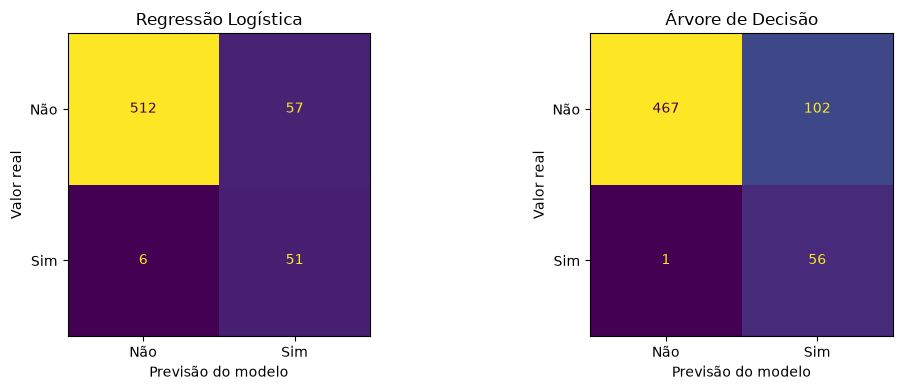

In [22]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, ConfusionMatrixDisplay

def metricas(y_real, y_prev):
    return {'acurácia': accuracy_score(y_real, y_prev), 'recall': recall_score(y_real, y_prev),
            'precisão': precision_score(y_real, y_prev), 'F1': f1_score(y_real, y_prev)}

resultados = pd.DataFrame({'Regressão Logística': metricas(y_test, prev_logistica),
                           'Árvore de Decisão': metricas(y_test, prev_arvore)}).round(3)
display(resultados)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nome, prev) in zip(axes, [('Regressão Logística', prev_logistica), ('Árvore de Decisão', prev_arvore)]):
    ConfusionMatrixDisplay.from_predictions(y_test, prev, display_labels=['Não', 'Sim'], ax=ax, colorbar=False)
    ax.set_title(nome)
    ax.set_xlabel('Previsão do modelo')
    ax.set_ylabel('Valor real')
plt.tight_layout()
plt.show()

No teste, a Regressão Logística avisou 51 dos 57 casos que iam ficar críticos (recall 0,89), contra 56 da Árvore de Decisão (0,98). A acurácia quase não diz nada aqui, um modelo que respondesse sempre "não" teria cerca de 91% no teste.

A logística deixou passar 6 casos (falsos negativos) e a árvore só 1. Nesses casos o paciente não recebe o aviso antecipado, mas a regra da pulseira continua alertando quando ele chega ao nível crítico. Em troca, a árvore deu muito mais alarmes falsos, sendo 102 contra 57 da logística (precisão 0,35 contra 0,47). Aceitamos alarmes falsos porque, na sala de espera, um alarme falso custa uma verificação a mais da equipe, enquanto um caso perdido custa o atendimento atrasado, por isso priorizamos o recall. Só que a árvore avisou 158 leituras e só 56 eram casos reais, e muitos alarmes falsos podem fazer a equipe passar a ignorar os avisos. A logística também ficou melhor na acurácia (0,90 contra 0,84) e no F1 (0,62 contra 0,52).

Como o teste tem só 21 pacientes, essas diferenças podem ser efeito do sorteio, por isso a escolha foi feita pela validação cruzada, olhando o equilíbrio entre recall e precisão. O teste mostrou o mesmo padrão da validação, com a árvore na frente no recall e a logística na precisão.

In [23]:
# cenário de cada falso positivo no teste
teste = base.loc[~no_treino]
falsos = pd.DataFrame({
    'Regressão Logística': teste.loc[(prev_logistica == 1) & (y_test == 0), 'cenario_simulado'].value_counts(),
    'Árvore de Decisão': teste.loc[(prev_arvore == 1) & (y_test == 0), 'cenario_simulado'].value_counts(),
}).reindex(ordem).fillna(0).astype(int)
falsos

,Regressão Logística,Árvore de Decisão
cenario_simulado,,
ESTAVEL,0,0
FC_ELEVANDO,6,14
SPO2_CAINDO,21,29
COMBINADO,13,11
RECUPERACAO,17,48


Nenhum alarme falso aconteceu em paciente do cenário estável, nos dois modelos. Todos foram em pacientes que estavam de fato piorando, mas que não chegaram ao nível crítico dentro da janela de 10 minutos. Na Regressão Logística, 37 dos 57 alarmes falsos foram em pacientes que ficaram críticos em algum momento da espera, só que depois da janela. A árvore concentrou 48 dos 102 alarmes falsos em pacientes da recuperação, que pioram e depois voltam ao normal. Ou seja, boa parte do "falso" vem do corte rígido do nosso alvo, e não de alarmes à toa. Por isso aceitar uma precisão mais baixa em troca do recall faz sentido, pois o aviso ajuda a equipe a olhar esses pacientes mais cedo, desde que a precisão não fique tão baixa quanto a da árvore.

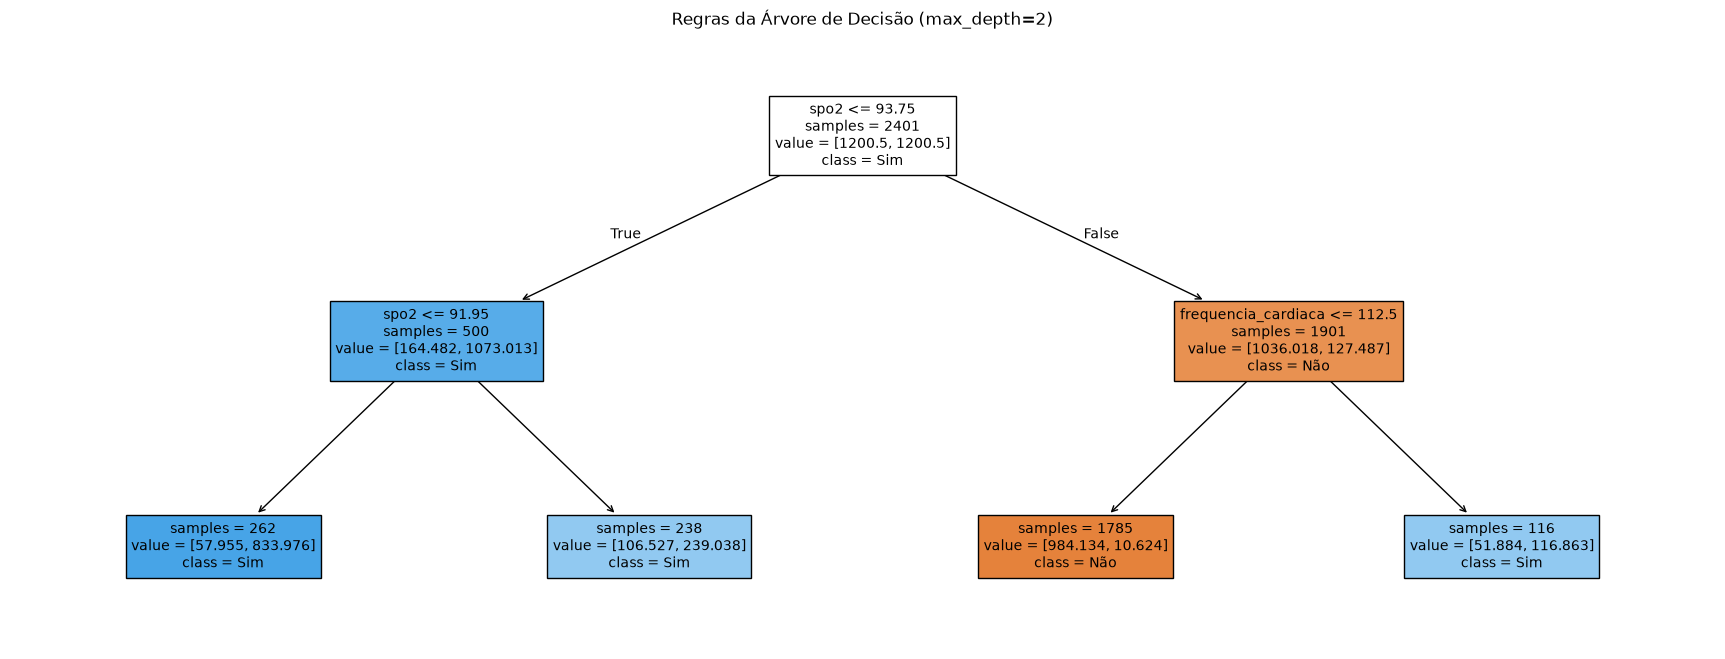

In [24]:
from sklearn.tree import plot_tree

# desenho da árvore, cada caixa é uma pergunta, e as folhas dizem a previsão (laranja = Não, azul = Sim)
plt.figure(figsize=(22, 8))
plot_tree(arvore, feature_names=features, class_names=['Não', 'Sim'], filled=True, impurity=False, fontsize=10)
plt.title('Regras da Árvore de Decisão (max_depth=2)')
plt.show()

A árvore mostra como ela decide. A primeira pergunta é a saturação de oxigênio, com SpO2 abaixo de cerca de 93,8%, ela já tende a indicar que o paciente vai ficar crítico. Com a saturação normal, uma frequência cardíaca acima de cerca de 112 bpm também indica risco, e abaixo disso a árvore não avisa. Isso combina com a EDA, onde FC e SpO2 foram os sinais que mais separaram os cenários. A temperatura não aparece nas perguntas dessa árvore de 2 níveis. São regras simples, por isso a árvore avisa muitas leituras que não chegam a ficar críticas. Essas regras ajudam a explicar para a equipe por que um paciente recebeu o aviso.

# 6. Aplicação prática

In [25]:
# simulação, as leituras de um paciente do teste chegam uma a uma, como na pulseira
def estado_pulseira(fc, spo2, temp):
    # mesma regra do monitor em Python
    if fc >= 130 or spo2 < 90 or temp >= 39.0:
        return 'CRÍTICO'
    elif fc >= 110 or fc < 50 or spo2 < 95 or temp >= 37.8:
        return 'ATENÇÃO'
    return 'NORMAL'

def acompanhar(paciente_id):
    leituras = df[df['paciente_id'] == paciente_id]
    for _, leitura in leituras.iterrows():
        estado = estado_pulseira(leitura['frequencia_cardiaca'], leitura['spo2'], leitura['temperatura'])
        chance = logistica.predict_proba(scaler.transform(leitura[features].to_frame().T))[0, 1]
        aviso = '<< AVISO DO MODELO' if estado != 'CRÍTICO' and chance >= 0.5 else ''
        print(f"{leitura['tempo_espera_min']:>3.0f} min | FC {leitura['frequencia_cardiaca']:>3.0f} | "
              f"SpO2 {leitura['spo2']:>5.1f} | Temp {leitura['temperatura']:>4.1f} | pulseira: {estado:<8} | chance de ficar crítico: {chance:>4.0%} {aviso}")
        if estado == 'CRÍTICO':
            break  # a partir daqui a regra da pulseira já está alertando

acompanhar(4)  # paciente do teste, o modelo nunca viu as leituras dele

  0 min | FC  86 | SpO2  95.4 | Temp 36.0 | pulseira: NORMAL   | chance de ficar crítico:   6% 
  2 min | FC  87 | SpO2  95.9 | Temp 36.1 | pulseira: NORMAL   | chance de ficar crítico:   3% 
  4 min | FC  87 | SpO2  95.0 | Temp 36.1 | pulseira: NORMAL   | chance de ficar crítico:  11% 
  6 min | FC  86 | SpO2  95.3 | Temp 36.1 | pulseira: NORMAL   | chance de ficar crítico:   6% 
  8 min | FC  93 | SpO2  95.5 | Temp 36.0 | pulseira: NORMAL   | chance de ficar crítico:   6% 
 10 min | FC  93 | SpO2  95.8 | Temp 36.2 | pulseira: NORMAL   | chance de ficar crítico:   4% 
 12 min | FC  94 | SpO2  95.3 | Temp 36.3 | pulseira: NORMAL   | chance de ficar crítico:  12% 
 14 min | FC  92 | SpO2  94.8 | Temp 36.4 | pulseira: ATENÇÃO  | chance de ficar crítico:  18% 
 16 min | FC  95 | SpO2  94.4 | Temp 36.4 | pulseira: ATENÇÃO  | chance de ficar crítico:  36% 
 18 min | FC  96 | SpO2  94.1 | Temp 36.4 | pulseira: ATENÇÃO  | chance de ficar crítico:  44% 
 20 min | FC  96 | SpO2  94.2 | Temp 36.

O paciente 4, por exemplo, entrou em estado de atenção aos 14 minutos. Só pela pulseira, a equipe não saberia se ele ia piorar ou não, porque muitos pacientes passam pela atenção e nunca chegam ao crítico. Aos 22 minutos o modelo avisou que ele estava indo para o crítico, e a crise só veio aos 36 minutos, ou seja, 14 minutos de antecedência. Com isso, a equipe médica já poderia avaliar esse paciente antes da crise e talvez evitar que ele chegasse ao estado crítico.

In [26]:
# quando o modelo avisou se o paciente iria ficar crítico e com quanto tempo de antecendência
linhas = []
for pid in teste_ids:
    leituras = df[df['paciente_id'] == pid]
    chance = logistica.predict_proba(scaler.transform(leituras[features]))[:, 1]
    aviso = (chance >= 0.5) & (leituras['critico'] == 0)
    critico = leituras['critico'] == 1
    t_critico = leituras.loc[critico, 'tempo_espera_min'].min() if critico.any() else None
    antes = aviso & ((leituras['tempo_espera_min'] < t_critico) if t_critico is not None else True)
    t_aviso = leituras.loc[antes, 'tempo_espera_min'].min() if antes.any() else None
    linhas.append({'paciente_id': pid, 'cenário': leituras['cenario_simulado'].iloc[0],
                   'ficou crítico (min)': t_critico, 'primeiro aviso (min)': t_aviso})

acompanhamento = pd.DataFrame(linhas).sort_values('paciente_id')
acompanhamento['antecedência (min)'] = acompanhamento['ficou crítico (min)'] - acompanhamento['primeiro aviso (min)']

criticos = acompanhamento.dropna(subset=['ficou crítico (min)'])
print('Pacientes do teste que ficaram críticos:', len(criticos))
print('Avisados antes pelo modelo:', criticos['antecedência (min)'].notna().sum())
print('Antecedência mediana:', criticos['antecedência (min)'].median(), 'min')
acompanhamento

Pacientes do teste que ficaram críticos: 11
Avisados antes pelo modelo: 10
Antecedência mediana: 17.0 min


,paciente_id,cenário,ficou crítico (min),primeiro aviso (min),antecedência (min)
0,4,COMBINADO,36.0,22.0,14.0
19,14,COMBINADO,34.0,14.0,20.0
4,15,RECUPERACAO,24.0,NaN,NaN
1,16,ESTAVEL,NaN,NaN,NaN
13,17,FC_ELEVANDO,54.0,42.0,12.0
9,21,ESTAVEL,NaN,NaN,NaN
5,28,SPO2_CAINDO,64.0,38.0,26.0
6,30,RECUPERACAO,NaN,26.0,NaN
10,37,FC_ELEVANDO,NaN,58.0,NaN
16,39,COMBINADO,48.0,26.0,22.0


Dos 11 pacientes do teste que ficaram críticos, 10 foram avisados antes pelo modelo, com uma antecedência mediana de 17 minutos. Só o paciente 15, do cenário de recuperação, passou sem aviso, e nenhum paciente estável recebeu aviso. Isso beneficia o paciente na espera, que ia piorar e pode ser avaliado antes. Também ajuda a equipe a organizar a espera, dando atenção primeiro a quem mais vai piorar.

O paciente é o centro da solução, e o nosso objetivo é que ninguém piore na espera do pronto-socorro sem que a equipe perceba. Esses resultados vêm de uma simulação, com pacientes e cenários criados por nós. A integração do modelo com a pulseira em tempo real não foi implementada e fica como evolução futura, assim como a validação com dados reais de um pronto-socorro.

# 7. Conclusão

A nossa solução olha para um problema real do pronto-socorro, pacientes que esperam muito tempo e acabam piorando durante essa espera sem que ninguém perceba. O objetivo do modelo é prever se a leitura da pulseira vai ficar crítica nos próximos 10 minutos, pela mesma regra de crítico da pulseira (FC, SpO2 e temperatura), para que a equipe consiga agir antes da crise. Ele usa só dados da pulseira (FC, SpO2, temperatura e as variações deles) e o tempo de espera, e não usa pressão arterial.

O modelo escolhido foi a Regressão Logística, porque na validação cruzada ela teve um equilíbrio melhor entre recall (0,92) e precisão (0,43) que o da árvore de profundidade 2. A árvore de profundidade 2 teve recall maior (0,97), mas uns 6 em cada 10 avisos dela eram alarme falso, e isso faz a equipe parar de confiar no aviso. Priorizamos o recall porque não queremos que pacientes que vão piorar passem sem aviso, mas sem aceitar alarme demais.

Na aplicação prática, 10 dos 11 pacientes do teste que ficaram críticos foram avisados antes, com uma antecedência mediana de 17 minutos. É um resultado bom para uma primeira versão, mas vem de poucos pacientes de teste.

A maior limitação da nossa solução é que o alvo é experimental e os dados foram simulados por nós. O modelo aprende o padrão da simulação, e para uso real seriam necessários dados de pacientes de pronto-socorro.

Como melhorias futuras, queremos treinar o modelo com dados reais, integrar o modelo com a pulseira em tempo real e usar regras de crítico baseadas em fontes clínicas.